# Systemy AI – Laboratorium 8
## Zadanie: sieć neuronowa dla Fashion-MNIST

**Fashion-MNIST** to „trudniejszy MNIST”: 70 000 zdjęć ubrań 28 × 28 pikseli w 10 klasach (koszulka, spodnie, sweter, sukienka, płaszcz, sandał, koszula, sneakers, torebka, botek). Format jest identyczny jak w MNIST, więc kod z wzoru (`SystemyAI_Lab8_wzor.ipynb`) przenosi się prawie bez zmian – ale wyniki będą inne.

Twoje zadanie: porównać regresję softmax z dwiema sieciami, wybrać model na zbiorze walidacyjnym, ocenić go raz na teście i sprawdzić, które ubrania model myli.

**Czas:** każdy model uczy się 5 epok, ok. 30–60 s na CPU w Colabie.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane
1. Wczytaj `datasets.FashionMNIST` (`root="data"`, `download=True`, `transform=transforms.ToTensor()`) – część treningową do `train_full`, testową do `test_set`.
2. Podziel `train_full` na `train_set` (50 000) i `val_set` (10 000): `random_split(..., generator=torch.Generator().manual_seed(42))`.
3. Utwórz `train_loader` (batch 128, `shuffle=True`), `val_loader` i `test_loader` (batch 1000).
4. Wyświetl 10 pierwszych obrazów treningowych z **nazwami** klas z listy `klasy` poniżej.

In [1]:
klasy = ["koszulka", "spodnie", "sweter", "sukienka", "płaszcz",
         "sandał", "koszula", "sneakers", "torebka", "botek"]

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 197kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.0MB/s]


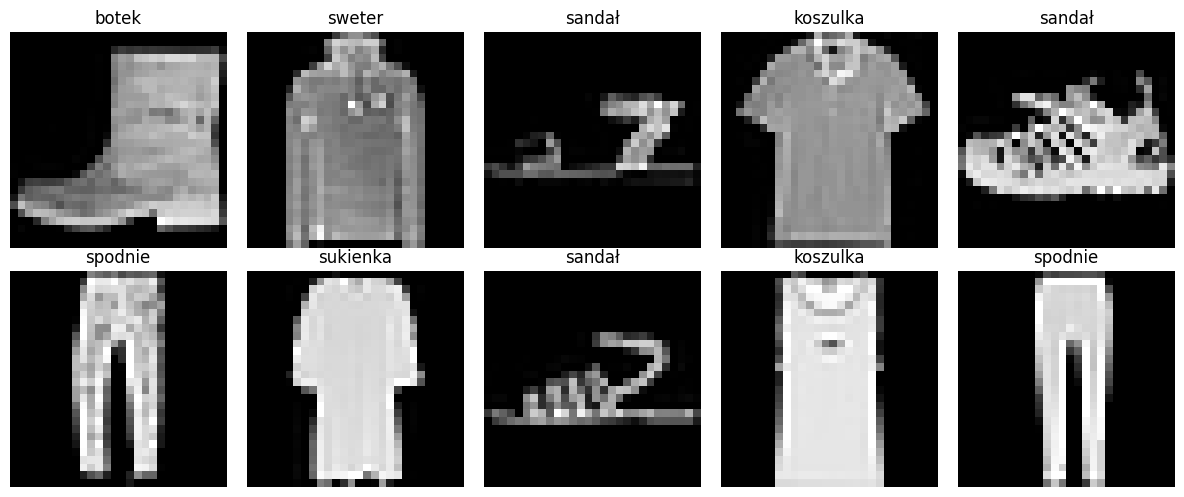

In [2]:
# Twoje rozwiązanie
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
train_full = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
test_set = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)
train_set, val_set = random_split(
    train_full,
    [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=1000, shuffle=False)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False)
plt.figure(figsize=(12, 5))
for i in range(10):
    image, label = train_set[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(klasy[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [3]:
# TEST
assert len(train_set) == 50_000 and len(val_set) == 10_000 and len(test_set) == 10_000
assert tuple(train_full[0][0].shape) == (1, 28, 28)
print("1 OK")

1 OK


---
## 2. Funkcje uczenia i oceny
Napisz (lub przenieś z wzoru i zrozum!) trzy funkcje:
- `epoka_uczenia(model, loader, optimizer)` – jedna epoka uczenia z `model.train()`,
- `ocen(model, loader)` – zwraca `(strata, accuracy)` z `model.eval()` i `torch.no_grad()`,
- `trenuj(model, epochs=5, lr=1e-3)` – optymalizator Adam; po każdej epoce zapisuje accuracy na train i val w słowniku z kluczami `"train acc"`, `"val acc"` i go zwraca.

In [4]:
# Twoje rozwiązanie
def epoka_uczenia(model, loader, optimizer, loss_fn=nn.CrossEntropyLoss()):
    model.train()
    device = next(model.parameters()).device
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(x)
        loss = loss_fn(outputs, y)
        loss.backward()
        optimizer.step()
def ocen(model, loader, loss_fn=nn.CrossEntropyLoss()):
    model.eval()
    device = next(model.parameters()).device
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            loss = loss_fn(outputs, y)
            total_loss += loss.item() * len(y)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == y).sum().item()
            total += len(y)
    return total_loss / total, correct / total
def trenuj(model, epochs=5, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train acc": [], "val acc": []}
    for epoch in range(epochs):
        epoka_uczenia(model, train_loader, optimizer)
        train_loss, train_acc = ocen(model, train_loader)
        val_loss, val_acc = ocen(model, val_loader)
        history["train acc"].append(train_acc)
        history["val acc"].append(val_acc)
        print(f"Epoka {epoch+1}/{epochs} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")
    return history

---
## 3. Model bazowy: regresja softmax
`torch.manual_seed(0)`, potem `model_soft = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))` i `hist_soft = trenuj(model_soft)`.

In [5]:
# Twoje rozwiązanie
torch.manual_seed(0)
model_soft = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 10)
)
hist_soft = trenuj(model_soft)

Epoka 1/5 | Train Acc: 0.8159 | Val Acc: 0.8105
Epoka 2/5 | Train Acc: 0.8308 | Val Acc: 0.8282
Epoka 3/5 | Train Acc: 0.8445 | Val Acc: 0.8386
Epoka 4/5 | Train Acc: 0.8465 | Val Acc: 0.8376
Epoka 5/5 | Train Acc: 0.8519 | Val Acc: 0.8458


In [6]:
# TEST
assert len(hist_soft["val acc"]) == 5
assert 0.78 < hist_soft["val acc"][-1] < 0.88
print("3 OK")

3 OK


---
## 4. Dwie sieci
Przed każdym modelem `torch.manual_seed(0)`:
- `model_maly`: `Flatten → Linear(784, 128) → ReLU → Linear(128, 10)` → `hist_maly`,
- `model_duzy`: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)` → `hist_duzy`.

Zbierz wyniki trzech modeli w `pd.DataFrame` o nazwie `wyniki` (indeks: `"softmax"`, `"sieć mała"`, `"sieć duża"`; kolumny: `"parametry"`, `"train acc"`, `"val acc"` – wartości po ostatniej epoce) i narysuj krzywe **val acc** wszystkich trzech modeli na jednym wykresie.

Epoka 1/5 | Train Acc: 0.8443 | Val Acc: 0.8404
Epoka 2/5 | Train Acc: 0.8608 | Val Acc: 0.8557
Epoka 3/5 | Train Acc: 0.8686 | Val Acc: 0.8570
Epoka 4/5 | Train Acc: 0.8761 | Val Acc: 0.8686
Epoka 5/5 | Train Acc: 0.8745 | Val Acc: 0.8626
Epoka 1/5 | Train Acc: 0.8492 | Val Acc: 0.8410
Epoka 2/5 | Train Acc: 0.8627 | Val Acc: 0.8615
Epoka 3/5 | Train Acc: 0.8855 | Val Acc: 0.8724
Epoka 4/5 | Train Acc: 0.8831 | Val Acc: 0.8725
Epoka 5/5 | Train Acc: 0.8974 | Val Acc: 0.8817


,parametry,train acc,val acc
softmax,7850,0.85194,0.8458
sieć mała,101770,0.87446,0.8626
sieć duża,235146,0.89742,0.8817


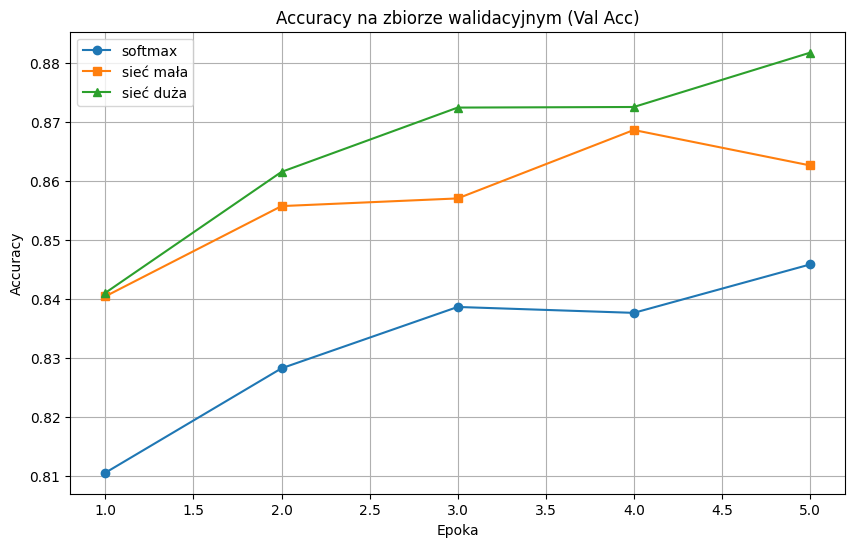

In [7]:
# Twoje rozwiązanie
import pandas as pd
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
torch.manual_seed(0)
model_maly = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
hist_maly = trenuj(model_maly)
torch.manual_seed(0)
model_duzy = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
hist_duzy = trenuj(model_duzy)
wyniki = pd.DataFrame(
    index=["softmax", "sieć mała", "sieć duża"],
    columns=["parametry", "train acc", "val acc"]
)
wyniki.loc["softmax"] = [count_parameters(model_soft), hist_soft["train acc"][-1], hist_soft["val acc"][-1]]
wyniki.loc["sieć mała"] = [count_parameters(model_maly), hist_maly["train acc"][-1], hist_maly["val acc"][-1]]
wyniki.loc["sieć duża"] = [count_parameters(model_duzy), hist_duzy["train acc"][-1], hist_duzy["val acc"][-1]]
display(wyniki)
plt.figure(figsize=(10, 6))
epochs = range(1, 6)
plt.plot(epochs, hist_soft["val acc"], 'o-', label="softmax")
plt.plot(epochs, hist_maly["val acc"], 's-', label="sieć mała")
plt.plot(epochs, hist_duzy["val acc"], '^-', label="sieć duża")
plt.title("Accuracy na zbiorze walidacyjnym (Val Acc)")
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
# TEST
assert list(wyniki.index) == ["softmax", "sieć mała", "sieć duża"]
assert wyniki.loc["sieć mała", "parametry"] == 101_770 and wyniki.loc["sieć duża", "parametry"] == 235_146
assert wyniki.loc["sieć mała", "val acc"] > wyniki.loc["softmax", "val acc"]
print("4 OK")

4 OK


*Twoja odpowiedź:*
1. Ile zyskuje sieć względem softmaksu na Fashion-MNIST, a ile zyskiwała na MNIST (wzór)? Skąd różnica?
2. Czy duża sieć jest wyraźnie lepsza od małej? Czy 2,3 razy więcej parametrów się opłaca?
3. Porównaj train acc i val acc dla każdego modelu. Gdzie różnica jest największa i co może oznaczać?

1 Sieć duża zyskuje względem softmaksu ok 3,6pp na Fashion-MNIST (88,17% vs 84,58%), a sieć mała ok 1,7pp (86,26% vs 84,58%). Na zwykłym MNIST ta różnica była większa i wynosiła ok 5-6pp. Wynika to stąd, że Fashion-MNIST zawiera znacznie bardziej skomplikowane i szczegółowe obrazy ubrań niż proste odręczne cyfry z MNIST, przez co prostej sieci gęstej trudniej osiągnąć bardzo wysoki wynik.

2 Duża sieć jest lepsza o niecałe 2 punkty procentowe od małej sieci (ok 1,91pp). Przyrost dokładności nie jest ogromny, ale przy wciąż niewielkiej liczbie parametrów (~235 tys) posiadanie 2,3 razy większego modelu zazwyczaj się opłaca, jeśli zależy nam na jak najwyższej jakości.

3 Porównanie train acc i val acc dla każdego modelu:
- softmax: 85,19% vs 84,58% (różnica ok 0,61pp),
- sieć mała: 87,45% vs 86,26% (różnica ok 1,19pp),
- sieć duża: 89,74% vs 88,17% (różnica ok 1,57pp).

Różnica jest największa w sieci dużej i oznacza początek lekkiego przeuczenia - większy model zaczyna mocniej dopasowywać się do zbioru treningowego kosztem generalizacji.

---
## 5. Ocena końcowa i błędy
1. `najlepszy` – nazwa modelu z najwyższym `val acc` w tabeli `wyniki`; `model_koncowy` – ten model.
2. `acc_test` – accuracy na zbiorze **testowym** (jedyny raz, kiedy go używasz).
3. Zbierz predykcje dla całego zbioru testowego (`y_true`, `y_pred` jako tablice NumPy) i narysuj macierz pomyłek z nazwami klas (`ConfusionMatrixDisplay.from_predictions`, `xticks_rotation=45`).
4. Wypisz 3 pary klas (prawdziwa → przewidziana), które model myli najczęściej.

Najlepszy model: sieć duża
Dokładność na teście (acc_test): 0.8751


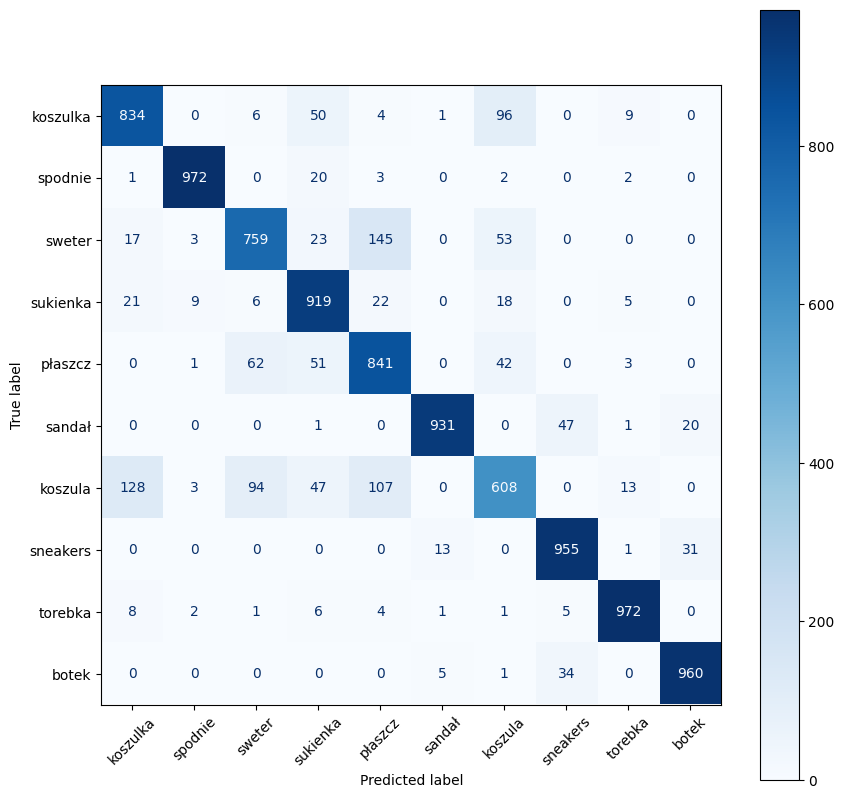

Trzy najczęściej mylone pary klas (prawdziwa -> przewidziana):
- sweter -> płaszcz (145 razy)
- koszula -> koszulka (128 razy)
- koszula -> płaszcz (107 razy)


In [9]:
# Twoje rozwiązanie
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
najlepszy = wyniki["val acc"].idxmax()
if najlepszy == "softmax":
    model_koncowy = model_soft
elif najlepszy == "sieć mała":
    model_koncowy = model_maly
else:
    model_koncowy = model_duzy
_, acc_test = ocen(model_koncowy, test_loader)
print(f"Najlepszy model: {najlepszy}")
print(f"Dokładność na teście (acc_test): {acc_test:.4f}")
y_true = []
y_pred = []
model_koncowy.eval()
with torch.no_grad():
    for x, y in test_loader:
        outputs = model_koncowy(x)
        predictions = outputs.argmax(dim=1)
        y_true.extend(y.numpy())
        y_pred.extend(predictions.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
fig, ax = plt.subplots(figsize=(10, 10))
cm_disp = ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=klasy,
    xticks_rotation=45,
    ax=ax,
    cmap='Blues'
)
plt.show()
cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)
flat_indices = np.argsort(cm.flatten())[::-1][:3]
print("Trzy najczęściej mylone pary klas (prawdziwa -> przewidziana):")
for idx in flat_indices:
    true_class_idx, pred_class_idx = divmod(idx, len(klasy))
    count = cm[true_class_idx, pred_class_idx]
    print(f"- {klasy[true_class_idx]} -> {klasy[pred_class_idx]} ({count} razy)")

In [10]:
# TEST
assert najlepszy == wyniki["val acc"].idxmax()
assert 0.82 < acc_test < 0.92
assert len(y_true) == len(y_pred) == 10_000
print("5 OK")

5 OK


*Twoja odpowiedź:* które klasy model myli najczęściej? Czy człowiek też miałby z nimi kłopot na obrazku 28 × 28? Która klasa jest najłatwiejsza i dlaczego?

Model najczęściej myli ze sobą następujące pary klas: sweter z płaszczem, koszulę z koszulką oraz koszulę z płaszczem.

Człowiek również miałby z nimi duży kłopot na tak małym obrazku o rozmiarze 28x28px w skali szarości, ponieważ kontury tych ubrań są bardzo podobne, a szczegóły ulegają rozmyciu.

Najłatwiejszą klasą dla modelu są spodnie oraz torebka. Dzieje się tak, ponieważ spodnie mają bardzo charakterystyczny podłużny kształt z dwiema nogawkami, a torebka ma zwartą strukturę - to wyraźnie odróżnia je od reszty ubrań nakładanych na tułów.

---
## 6. Dla chętnych
1. Naucz `model_duzy` od nowa przez **15 epok** i narysuj train acc i val acc. Od której epoki krzywe zaczynają się rozjeżdżać? (To przeuczenie – temat następnych zajęć.)
2. Zamień `ReLU` na `Sigmoid` w małej sieci. Jak zmienia się szybkość uczenia?
3. Narysuj 10 obrazów testowych, na których model się pomylił, z podpisem „przewidziane (prawdziwe)”.

Epoka 1/15 | Train Acc: 0.8492 | Val Acc: 0.8410
Epoka 2/15 | Train Acc: 0.8627 | Val Acc: 0.8615
Epoka 3/15 | Train Acc: 0.8855 | Val Acc: 0.8724
Epoka 4/15 | Train Acc: 0.8831 | Val Acc: 0.8725
Epoka 5/15 | Train Acc: 0.8974 | Val Acc: 0.8817
Epoka 6/15 | Train Acc: 0.8968 | Val Acc: 0.8799
Epoka 7/15 | Train Acc: 0.9021 | Val Acc: 0.8840
Epoka 8/15 | Train Acc: 0.9087 | Val Acc: 0.8865
Epoka 9/15 | Train Acc: 0.9084 | Val Acc: 0.8863
Epoka 10/15 | Train Acc: 0.9159 | Val Acc: 0.8881
Epoka 11/15 | Train Acc: 0.9181 | Val Acc: 0.8894
Epoka 12/15 | Train Acc: 0.9213 | Val Acc: 0.8918
Epoka 13/15 | Train Acc: 0.9262 | Val Acc: 0.8937
Epoka 14/15 | Train Acc: 0.9227 | Val Acc: 0.8864
Epoka 15/15 | Train Acc: 0.9210 | Val Acc: 0.8842


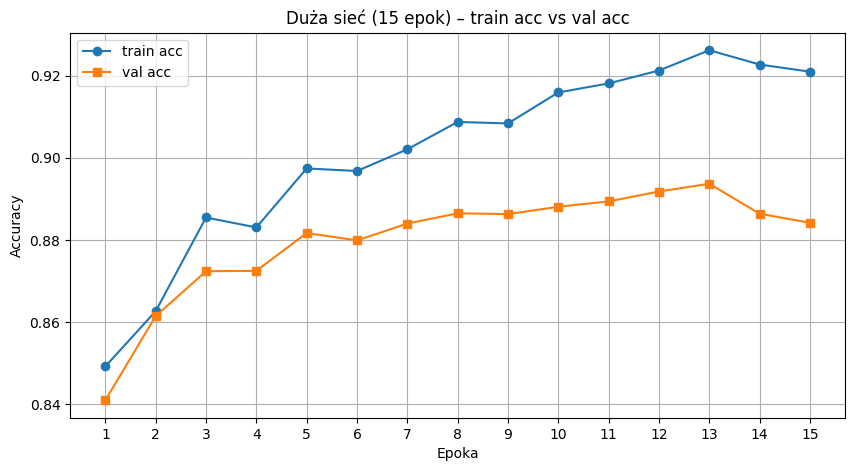

In [11]:
torch.manual_seed(0)
model_duzy_15 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
hist_duzy_15 = trenuj(model_duzy_15, epochs=15)
plt.figure(figsize=(10, 5))
epochs_15 = range(1, 16)
plt.plot(epochs_15, hist_duzy_15["train acc"], "o-", label="train acc")
plt.plot(epochs_15, hist_duzy_15["val acc"], "s-", label="val acc")
plt.title("Duża sieć – train acc vs val acc")
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.xticks(epochs_15)
plt.legend()
plt.grid(True)
plt.show()

Epoka 1/5 | Train Acc: 0.8192 | Val Acc: 0.8172
Epoka 2/5 | Train Acc: 0.8496 | Val Acc: 0.8436
Epoka 3/5 | Train Acc: 0.8623 | Val Acc: 0.8556
Epoka 4/5 | Train Acc: 0.8673 | Val Acc: 0.8635
Epoka 5/5 | Train Acc: 0.8723 | Val Acc: 0.8619


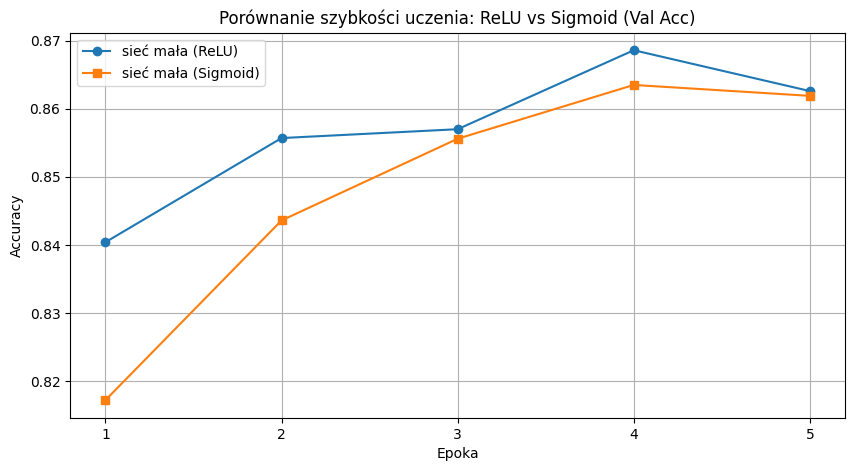

In [12]:
torch.manual_seed(0)
model_maly_sig = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.Sigmoid(),
    nn.Linear(128, 10)
)
hist_maly_sig = trenuj(model_maly_sig, epochs=5)

plt.figure(figsize=(10, 5))
epochs_5 = range(1, 6)
plt.plot(epochs_5, hist_maly["val acc"], "o-", label="sieć mała ReLU")
plt.plot(epochs_5, hist_maly_sig["val acc"], "s-", label="sieć mała Sigmoid")
plt.title("Porównanie szybkości uczenia: ReLU vs Sigmoid")
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.xticks(epochs_5)
plt.legend()
plt.grid(True)
plt.show()

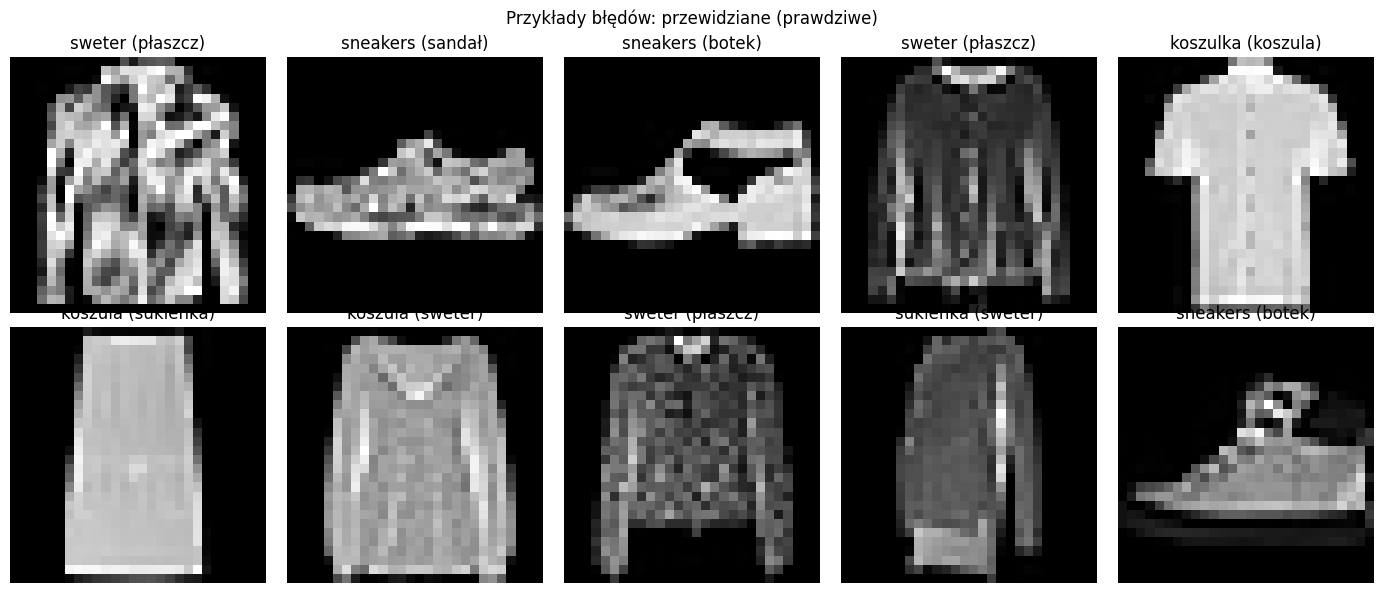

In [13]:
bledy_idx = np.where(y_pred != y_true)[0]

plt.figure(figsize=(14, 6))
for i, idx in enumerate(bledy_idx[:10]):
    image, true_label = test_set[idx]
    pred_label = y_pred[idx]
    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"{klasy[pred_label]} ({klasy[true_label]})")
    plt.axis("off")
plt.suptitle("Przykłady błędów: przewidziane (prawdziwe)")
plt.tight_layout()
plt.show()

1. Krzywe train acc i val acc zaczynają się zauważalnie rozjeżdżać od ok 5-7 epoki (różnica rośnie z ~1,57 pp w 5 epoce do ~1,81 pp w 7 epoce i ~2,22 pp w 8. epoce). W kolejnych epokach dokładność na zbiorze treningowym rośnie dalej (do 92,62% w 13 epoce), podczas gdy dokładność walidacyjna osiąga maksimum w 13 epoce (89,37%), a w epokach 14–15 zaczyna spadać do 88,42%, przy rozbieżności sięgającej ok 3,7pp. Jest to przykład przeuczenia.

2. Z funkcją Sigmoid sieć uczy się wyraźnie wolniej w początkowych epokach: po 1 epoce osiąga valacc=81,72% wobec 84,04% dla ReLU (różnica ok 2,32pp), a po 2 epoce 84,36% wobec 85,57%. Wynika to z tego, że pochodna funkcji sigmoidalnej przyjmuje małe wartości (maksymalnie 0,25, a przy dużych wartościach argumentu dąży do zera - zjawisko zanikającego gradientu), co spowalnia aktualizację wag. Ponieważ sieć ma tylko jedną warstwę ukrytą, po 3-5 epokach Sigmoid prawie dogania ReLU (86,19% vs 86,26% w 5 epoce).